# ARGUS-FEDER — How was this result produced?

A result is only as useful as what you know about how it was made. Which code
ran, against which snapshot of the data, with which cuts applied, and on which
shots — without those, two numbers that disagree cannot be told apart from two
numbers that were never comparable.

That record is kept separately from the data itself, in a metadata server that
pipelines write to as they run. This notebook asks it the questions a scientist
asks when they meet somebody else's result:

- what analyses have been run already, and by what method?
- what inputs and parameters did each stage actually use?
- are two results comparable, or were they computed on different ground?
- can I get back to the file this came from?

Questions are typed in plain English into an `%%ask` cell. The agent decides
what to look up, writes and runs its own code, and reports back.

In [ ]:
%reset

## 1 — What work has already been recorded?

The opening question, and the one that decides whether any of the rest is worth
asking. A reader coming to a shared metadata server has no list of what is in
it.

**Expect:** the pipelines that are visible, what each one is for, and the stages
each ran — with the answer stated as what *this account* can see, since
authorisation is per user.

In [3]:
%%ask 
What computational pipelines have been recorded on the metadata server,
and what does each one do?

The CMF metadata server shows **two pipelines visible to your account** :

1. **`hello-toksearch`** — A single-stage pipeline that reads a list of three DIII-D shots, fetches the `ptdata:ip` plasma-current signal, and writes per-shot peak-current results to `peak_ip.parquet`. Its recorded summary says all three shots were processed successfully.

2. **`betan-nbi`** — A three-stage analysis of normalized beta and neutral-beam power:
   - **Shot list:** Selects shots using a recorded DIII-D database snapshot and a June 1–August 1, 2024 window; the run recorded 651 shots.
   - **Fetch:** Retrieves normalized beta, plasma current, and launched neutral-beam power. It records a normalized-beta rejection threshold of 10.0 and produced complete results for 534 shots.
   - **Analyze:** Fits the recorded expression `betan_max = a * pnbi_max_MW + b` using those 534 results, producing fit metrics and a plot.

These descriptions come from the pipelines’ recorded stages, parameters, artifacts, and lineage—not from inspecting their underlying data files. CMF records what ran and what it produced; it does not establish whether the analysis is scientifically correct. Nor does the visible list establish that no other pipelines were run or recorded for other users.

**Data files** : [Pipeline overview](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/deep_tok/_argus_feder_cmf_provenance_jupyterhub_sage_/cmf_pipeline_overview.json) lists the visible pipelines and counts; [hello-toksearch record](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/deep_tok/_argus_feder_cmf_provenance_jupyterhub_sage_/cmf_hello-toksearch_record.json) and [betan-nbi record](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/deep_tok/_argus_feder_cmf_provenance_jupyterhub_sage_/cmf_betan-nbi_record.json) contain the stage properties, artifacts, metrics, and lineage behind this summary.

## 2 — The method, stage by stage

The useful level of detail is not "a pipeline ran" but what each step was given.
A stage records the script it executed, the inputs it drew on, and the parameter
values in force — and which of those it records is the pipeline author's choice,
not a fixed schema.

**Expect:** per stage, the code that ran, the inputs and parameter values as
recorded, and what came out. Expect the parameters that are present to be
reported, and no claim about ones that are not.

In [4]:
%%ask 
Take the most substantial pipeline recorded there and lay out what each
stage did: the code that ran, the inputs and parameter values it used, 
and what it produced.

## Most substantial recorded pipeline: `betan-nbi`

Of the pipelines visible to this account, `betan-nbi` has the most recorded work: **three completed stages and seven artifacts** . Its recorded lineage is:

`data/shots.parquet` → `data/peaks.parquet` → `data/betan_vs_pnbi.png` and fit metrics.

| Stage | Recorded code and inputs | Parameters and work recorded | Outputs |
|---|---|---|---|
| **1. Shot list** | `betan_nbi/shot_list.py`; DIII-D database snapshot `d3drdb_20261006T135944Z` | Window: **2024-06-01 to 2024-08-01** . The stage produced a list of **651 shots** , from shot **198873** through **199805** . | `data/shots.parquet` (hash `2b7aa860fdcfb4d9bda7ac95f1fbd46e`) and shot-list metrics. |
| **2. Fetch** | `betan_nbi/fetch.py`; takes `data/shots.parquet` as its recorded upstream artifact | Signals: normalized beta `imas:equilibrium.time_slice.global_quantities.beta_normal`, plasma current `ptdata:ip`, and launched neutral-beam power `imas:nbi.unit.power_launched.data`. Recorded normalized-beta rejection threshold: **10.0 or above** . It processed **651 shots** : **534 complete** , **117 with errors** , in **173.7 seconds** . | `data/peaks.parquet` (hash `5846e8b2ae78464e7cf99c6ff459a656`) and fetch metrics. |
| **3. Analyze** | `betan_nbi/analyze.py`; takes `data/peaks.parquet` as its recorded upstream artifact | Recorded fit expression: `betan_max = a * pnbi_max_MW + b`. For **534 points** , the recorded fit metrics are slope **0.244567 per MW** , intercept **0.124677** , and Pearson &#36;r = 0.87514&#36;. | `data/betan_vs_pnbi.png` (hash `07d2895e97f8fe9e2ff2c0bb998bd631`) and fit metrics. |

**Code provenance:** All three executions name the same Git repository, `/fusion/projects/dt/sammuli/fdp_dev/scratch/cmf-hello/origin.git`, and the same recorded Python-environment artifact, `cmf_artifacts/python_env_db0e8a6b4888b8bf99f96469c512df25.yaml` (hash `db0e8a6b4888b8bf99f96469c512df25`). Their recorded Git start → end commits are:

- **Shot list:** `554a806f0f060adb91ff27f161ad2aae054c5a8e` → `99cd5a8c00040005786b5b50ca304c5b41a25cf5`
- **Fetch:** `99cd5a8c00040005786b5b50ca304c5b41a25cf5` → `3f9b08dbfab15e9fe5a1c3f7d7432589655999dc`
- **Analyze:** `3f9b08dbfab15e9fe5a1c3f7d7432589655999dc` → `f1285f9dcb05b0b5543ada2dbf2a9e67c6f9c4c3`

The metadata server records **script paths and commit identifiers, not the source-code text or dataset contents** . Thus this lays out what the executions recorded, but does not verify the scripts’ implementation or the fit’s scientific validity.

**Data files:** [Pipeline overview](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/deep_tok/_argus_feder_cmf_provenance_jupyterhub_sage_/cmf_stage_overview.json) contains the pipeline comparison; [complete `betan-nbi` provenance record](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/deep_tok/_argus_feder_cmf_provenance_jupyterhub_sage_/cmf_betan_stage_detail.json) contains every quoted execution property, metric, artifact, and lineage link.

## 3 — Are two results comparable?

This is the question provenance exists to answer. Two analyses of the same
physical quantity are not comparable merely because both are correct: a
different time window, a different cut, a different snapshot of the underlying
archive, or the same quantity fetched under a different naming scheme all make
the comparison invalid in ways no plot reveals.

**Expect:** the recorded parameters lined up side by side, and a verdict on
whether a direct comparison is defensible — naming the specific differences
rather than concluding in general terms.

In [5]:
%%ask 
Looking at the pipelines recorded there, are their results comparable
with one another? Compare what each actually used, and say what would 
prevent a direct comparison.

## Are the results comparable?

**Not directly.** The two pipelines visible to this account share one recorded signal identifier, `ptdata:ip`, but they select different sets of shots and report different quantities.

| | `hello-toksearch` | `betan-nbi` |
|---|---|---|
| **Shot input** | `shots.txt`; **3 shots** . The CMF record does not list their shot numbers. | DIII-D database snapshot `d3drdb_20261006T135944Z`, with a recorded **2024-06-01 to 2024-08-01** selection window; **651 shots** selected. |
| **Signals recorded** | `ptdata:ip` | `ptdata:ip`, plus IMAS normalized beta (`equilibrium.time_slice.global_quantities.beta_normal`) and launched NBI power (`nbi.unit.power_launched.data`). |
| **Processing recorded** | One peak-current stage; **3 of 3** shots reported OK. | Shot selection, fetch, then analysis. The fetch records a normalized-beta rejection threshold of **10.0 or above** ; **534** shots completed and **117** had errors. The analysis fits `betan_max = a * pnbi_max_MW + b` using **534 points** . |
| **Reported result** | Maximum peak plasma current across its shots: **0.905287 MA** ; per-shot results are referenced as `peak_ip.parquet`. | Beta-versus-NBI-power fit: slope **0.244567 per MW** , intercept **0.124677** , Pearson &#36;r = 0.87514&#36;; its intermediate results are referenced as `data/peaks.parquet`. |

The shared `ptdata:ip` identifier makes the *source of plasma-current data* comparable at the provenance level. It does **not** make **0.905287 MA** comparable to a beta–NBI fit coefficient or correlation: they measure different results. CMF also does not show whether the three `hello-toksearch` shots overlap the 651 selected by `betan-nbi`, or expose the artifact contents needed to match per-shot current values. The records use **different environment artifacts and Git commits** , so identical processing cannot be assumed. Nor does the metadata explain the 117 fetch errors well enough to assign them all to the beta threshold.

A direct numerical comparison would require the shot lists and per-shot outputs, a common shot selection, and confirmation that current peaks were computed with the same definition and processing. CMF provides references and hashes for those files, **not their contents** ; it cannot establish those conditions from these records alone.

**Data file** : [CMF comparability evidence](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/deep_tok/_argus_feder_cmf_provenance_jupyterhub_sage_/cmf_pipeline_comparability_evidence.json) contains both visible pipelines’ recorded executions, properties, artifacts, metrics, lineage, and cross-pipeline parameter table.

## 4 — Getting back to the file

A result points at files. The question is whether those files can be reached
from here, and what to do when they cannot.

**Expect:** the figure identified, with where it came from and the hash that
identifies it. Whether its contents can be retrieved is the point of the
question, and a clear answer either way is a good answer.

In [6]:
%%ask 
Show me the figure that one of these pipelines produced.

I can identify the figure produced by `betan-nbi`, but **I can’t display the original image from the metadata server** . CMF records its DVC location and hash, not the PNG bytes or a download URL. I haven’t substituted a chart reconstructed from the recorded fit metrics, because that would not be the pipeline’s figure.

**Recorded figure** : `data/betan_vs_pnbi.png`  
**Artifact hash** : `07d2895e97f8fe9e2ff2c0bb998bd631`  
**Recorded DVC location** : `betan-nbi:/fusion/projects/dt/sammuli/fdp_dev/scratch/cmf-hello/dvc-remote/files/md5/07/d2895e97f8fe9e2ff2c0bb998bd631`

If you provide the PNG in the notebook’s working folder, I can display that actual file.

## 5 — Asked without naming the source

The same question a colleague would ask in a corridor, with no mention of
metadata, provenance or pipelines. If prior work exists, it should surface; if
it does not, saying so is the answer.

**Expect:** either the prior analysis with its method and the conditions it
covered, or a plain statement that nothing matching has been recorded — and the
second phrased as nothing recorded, not as nothing done.

In [7]:
%%ask 
Has anyone already analysed how normalized beta varies with injected
neutral-beam power?

**Yes.** The CMF metadata server records a `betan-nbi` pipeline that analysed how maximum normalized beta varies with maximum launched neutral-beam power.

It selected **651 DIII-D shots** using a recorded June 1–August 1, 2024 window and database snapshot. Its fetch stage recorded **534 complete shots** and **117 with errors** . The analysis stage then fitted the 534 complete results with:

$$\mathrm{beta}_{N,\max}=a\,P_{\mathrm{NBI},\max}\;(\mathrm{MW})+b$$

The recorded fit metrics are **$a=0.244567$ per MW** , **$b=0.124677$** , and **Pearson $r=0.87514$** . The pipeline also produced a figure artifact named `data/betan_vs_pnbi.png`.

That establishes that an analysis **was recorded** , not that its fit has been independently checked. CMF holds the metrics and a reference to the figure, but not the underlying per-shot data or image bytes; the record also does not establish why each of the 117 shots had an error. This answer is scoped to pipelines visible to this account.

**Data files** : [Visible pipeline overview](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/deep_tok/_argus_feder_cmf_provenance_jupyterhub_sage_/beta_beam_visible_pipeline_overview.json) and [full `betan-nbi` provenance record](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/deep_tok/_argus_feder_cmf_provenance_jupyterhub_sage_/beta_beam_pipeline_record.json) contain the recorded counts, parameters, artifacts, and fit metrics quoted here.

## 6 — What this record does not establish

A closing question about the limits of the source rather than its contents. A
metadata server says what ran. It does not say whether the result was right,
and it does not describe how the underlying data reached the archive.

**Expect:** the distinction drawn explicitly — what the recorded numbers do and
do not license, what is absent because nobody recorded it, and which questions
belong to a different source entirely.

## What the records let us claim

For the two pipelines visible to this account, CMF establishes **what was recorded as run, with which identifiers and parameters, and which artifacts were produced** . It does not establish that the resulting measurements or scientific interpretation are correct.

| Pipeline | Claim supported by its record |
|---|---|
| `hello-toksearch` | A peak-current stage used the recorded signal `ptdata:ip` and an input artifact named `shots.txt`. It reported **3 shots OK out of 3** and a maximum peak plasma current of **0.905287 MA** . It produced `peak_ip.parquet`. |
| `betan-nbi` | Shot selection recorded a **2024-06-01 to 2024-08-01** window and database snapshot `d3drdb_20261006T135944Z`, yielding **651 shots** . Fetch used recorded identifiers for normalized beta, launched neutral-beam power, and `ptdata:ip`, with a normalized-beta rejection threshold of **10.0 or above** . It reported **534 complete shots** and **117 with errors** . Analysis reported a fit of maximum normalized beta against maximum launched NBI power on **534 points** : slope **0.244567 per MW** , intercept **0.124677** , and Pearson $r=0.87514$. It produced a figure artifact named `data/betan_vs_pnbi.png`. |

The recorded counts differ greatly, but these are **different shot cohorts and different analyses** , not two measurements of the same sample.


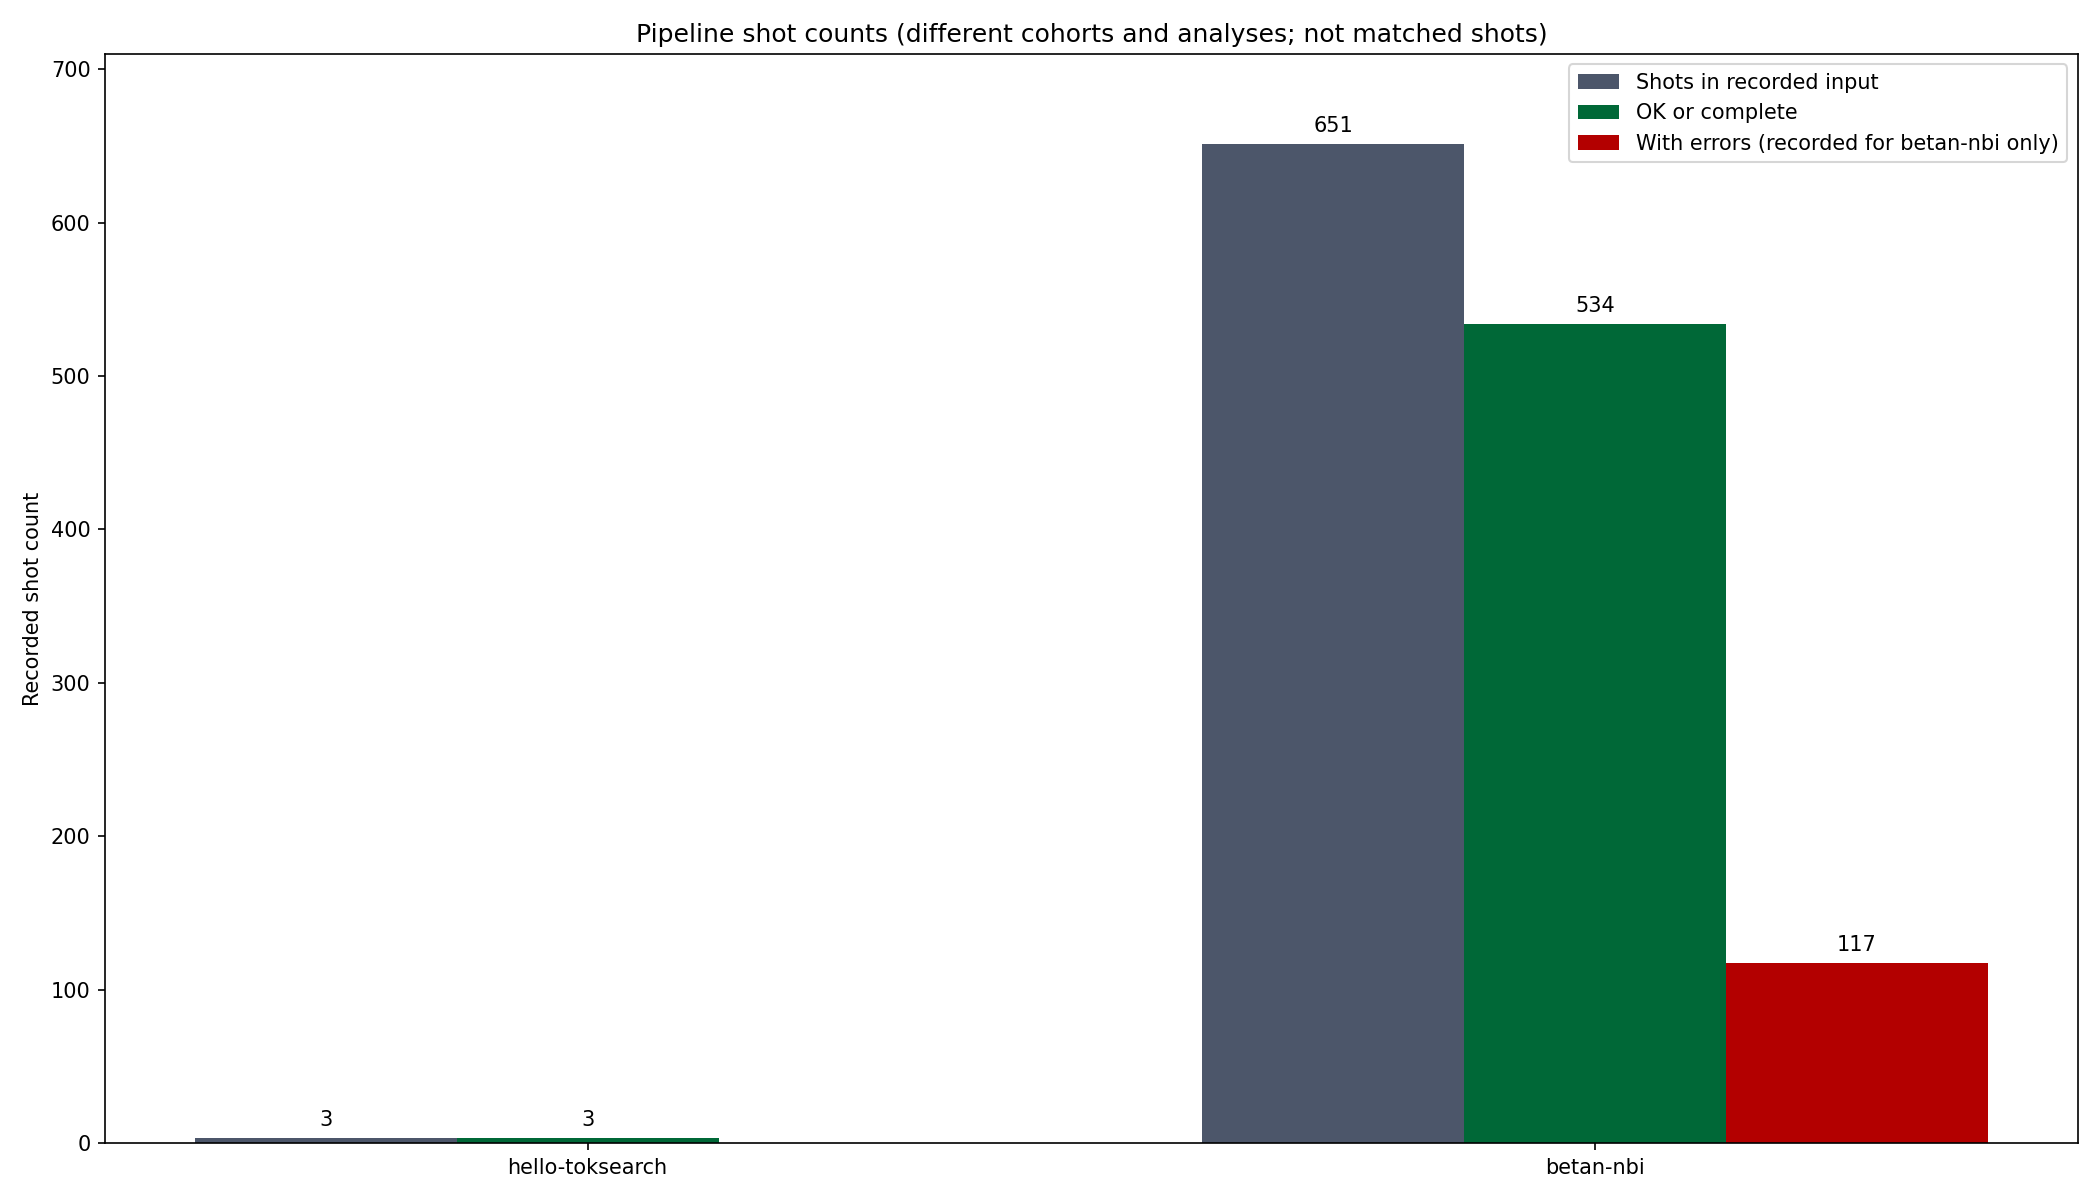

## What they are not sufficient to establish

- **A validated physical relationship or causation.** The beta–power coefficient and correlation are *reported fit outputs*. The record alone does not verify the underlying values, fit choices, uncertainties, confounding factors, or whether increasing beam power caused beta to increase. In particular, the recorded expression relates **per-shot maxima** ; it does not establish that each beta maximum occurred at the same time as its power maximum.
- **An unbiased or generalizable result.** The records do not identify why each of the **117** fetches had errors or establish how excluding them affected the fit. The recorded beta rejection threshold cannot, by itself, be treated as the explanation for those errors.
- **A direct comparison between the pipelines’ numerical results.** The current maximum in `hello-toksearch` and the beta–power fit in `betan-nbi` answer different questions. Although both record `ptdata:ip`, CMF does not expose the three shot numbers in `shots.txt` or the per-shot artifact contents needed to check overlap and compare like-for-like current calculations.
- **Independent reproducibility or verification of the figure.** CMF records Git commit identifiers, an environment artifact, hashes, and lineage. Re-running or checking the computation would additionally require access to the code, environment, input data, and artifact bytes. The figure’s recorded existence does not mean its image contents were examined here.
- **That these are all analyses ever performed.** They are the pipelines returned for this account; work not recorded in CMF or not visible to this account is outside this finding.

**Data files:** [Pipeline overview](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/deep_tok/_argus_feder_cmf_provenance_jupyterhub_sage_/cmf_claims_overview.json), [beta–NBI executions, metrics, artifacts, and lineage](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/deep_tok/_argus_feder_cmf_provenance_jupyterhub_sage_/cmf_claims_betan-nbi.json), [peak-current pipeline record](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/deep_tok/_argus_feder_cmf_provenance_jupyterhub_sage_/cmf_claims_hello-toksearch.json), and [shot counts behind the chart](/home/jovyan/work/_User-Persistent-Storage_CephBlock_/deep_tok/_argus_feder_cmf_provenance_jupyterhub_sage_/cmf_claims_shot_counts.json).

In [8]:
%%ask 
Given what is recorded for these pipelines, what do they let us claim,
and what would they not be sufficient to establish?